# Predicting Potential Research Collaborations Using Link Prediction
### Social Network Analysis — AAT Project

**Network:** NetScience co-authorship network · **Node:** researcher · **Edge:** co-authorship (undirected)  
**Goal:** predict hidden collaboration links with Common Neighbors, Jaccard, Adamic-Adar and Preferential Attachment.

This notebook imports every function from `main.py`, so the notebook, the script and all files in `results/` use the **same code and the same split** (seed 42). Results are deterministic: they do not change between runs or machines.

In [1]:
import sys
sys.path.insert(0, "..")          # make main.py importable
import numpy as np, pandas as pd, networkx as nx
import main as P
pd.options.display.float_format = "{:.3f}".format

## 1. Network preparation

In [2]:
G = P.load_and_prepare_graph()
print("Largest connected component:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")
print("Average degree:", round(sum(dict(G.degree()).values()) / G.number_of_nodes(), 4))
print("Density:", round(nx.density(G), 6))
print("Average clustering:", round(nx.average_clustering(G), 4))

Largest connected component: 379 nodes, 914 edges
Average degree: 4.8232
Density: 0.01276
Average clustering: 0.7412


## 2. 80/20 split and negative sampling (seed 42)
20% of the edges are hidden without isolating any researcher. Negative pairs are sampled from pairs that are **not connected in the original network**, so a hidden edge can never be a negative.

In [3]:
G_train, positives, negatives, metrics = P.run_split(G, P.SEED)
print("Training edges:", G_train.number_of_edges())
print("Positive test edges:", len(positives))
print("Negative test pairs:", len(negatives))
print("Negatives that are hidden edges:", len({frozenset(e) for e in negatives} & {frozenset(e) for e in positives}))

Training edges: 731
Positive test edges: 183
Negative test pairs: 183
Negatives that are hidden edges: 0


## 3. Metrics on this split
The 183 highest-scoring pairs are labelled as links, so Precision = Recall = F1. **Score ties are broken at random**: many pairs tie at score 0 for CN, Jaccard and Adamic-Adar, and a stable sort over a list that begins with the true links would favour them.

In [4]:
metrics

,Algorithm,Precision,Recall,F1,ROC-AUC,Precision@10,Precision@20
0,Common Neighbors,0.874,0.874,0.874,0.927,1.000,1.000
1,Jaccard,0.874,0.874,0.874,0.926,1.000,1.000
2,Adamic-Adar,0.896,0.896,0.896,0.928,1.000,1.000
3,Preferential Attachment,0.623,0.623,0.623,0.653,0.700,0.800


## 4. Robustness: 20 repeated splits (seeds 0–19)

In [5]:
frames = []
for seed in P.REPEAT_SEEDS:
    m = P.run_split(G, seed)[3]
    m.insert(0, "seed", seed)
    frames.append(m)
by_seed = pd.concat(frames, ignore_index=True)
summary = P.summarise(by_seed)
summary

,Algorithm,Precision,Recall,F1,ROC-AUC,Precision@10,Precision@20,Precision (sd),Recall (sd),F1 (sd),ROC-AUC (sd),Precision@10 (sd),Precision@20 (sd)
0,Common Neighbors,0.913,0.913,0.913,0.947,1.000,1.000,0.021,0.021,0.021,0.012,0.000,0.000
1,Jaccard,0.912,0.912,0.912,0.945,0.985,0.993,0.020,0.020,0.020,0.012,0.037,0.018
2,Adamic-Adar,0.914,0.914,0.914,0.950,1.000,1.000,0.022,0.022,0.022,0.012,0.000,0.000
3,Preferential Attachment,0.618,0.618,0.618,0.666,0.905,0.847,0.019,0.019,0.019,0.028,0.110,0.094


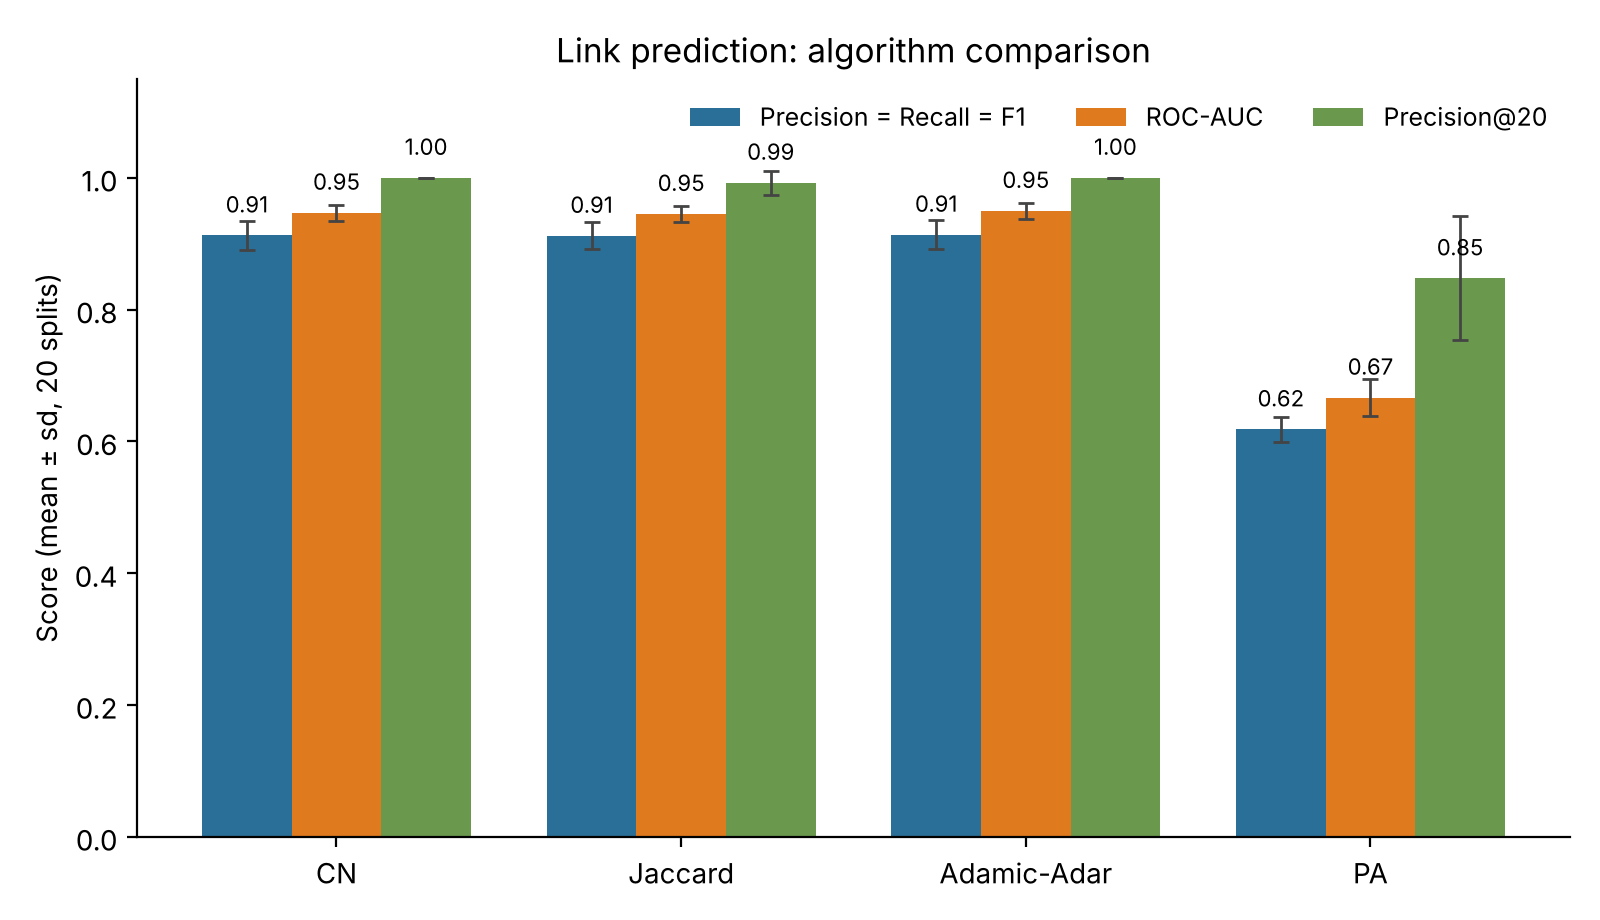

In [6]:
import matplotlib.pyplot as plt
from IPython.display import Image
P.plot_comparison(summary, "../results/algorithm_comparison.png")
Image("../results/algorithm_comparison.png")

## 5. Recommendations
**New collaborations:** rank every unlinked pair of the full network (ties in score are ordered by number of shared collaborators, then alphabetically).  
**Validation:** apply the same ranking to the seed-42 *training* graph and count how many of the Top-K pairs are hidden, i.e. real, collaborations.

In [7]:
recs = P.rank_candidates(G, 20)
for name, g in recs.groupby("Algorithm", sort=False):
    print(f"\n{name}: Top-10 new collaborations")
    display(g.head(10)[["Rank", "Researcher_1", "Researcher_2", "Score", "Common_Neighbors"]])

hits, _ = P.hit_rates(G_train, positives)
print("\nValidation on the training graph: Top-K pairs that are hidden real edges")
display(hits)


Common Neighbors: Top-10 new collaborations


,Rank,Researcher_1,Researcher_2,Score,Common_Neighbors
0,1,"ALBERT, R","PODANI, J",4.000,4
1,2,"ALBERT, R","SZATHMARY, E",4.000,4
2,3,"BRODER, A","SIVAKUMAR, D",4.000,4
3,4,"BRODER, A","UPFAL, E",4.000,4
4,5,"GIRALT, F","GLEISER, P",4.000,4
5,6,"HONG, H","JEONG, H",4.000,4
6,7,"MAGHOUL, F","SIVAKUMAR, D",4.000,4
7,8,"MAGHOUL, F","UPFAL, E",4.000,4
8,9,"SIVAKUMAR, D","STATA, R",4.000,4
9,10,"SIVAKUMAR, D","WIENER, J",4.000,4



Jaccard: Top-10 new collaborations


,Rank,Researcher_1,Researcher_2,Score,Common_Neighbors
20,1,"GIRALT, F","GLEISER, P",1.000,4
21,2,"EREZ, K","ROZENFELD, A",1.000,3
22,3,"GHIM, C","LEE, D",1.000,3
23,4,"GOLTSEV, A","SAMUKHIN, A",1.000,2
24,5,"GOMEZ, J","VAZQUEZPRADA, M",1.000,2
25,6,"JANSSEN, C","KOHLER, R",1.000,2
26,7,"LEYVRAZ, F","VAZQUEZ, F",1.000,2
27,8,"MUHAMAD, R","SABEL, C",1.000,2
28,9,"DARBYDOWMAN, K","ERGUN, G",1.000,1
29,10,"DEARCANGELIS, L","ROUX, S",1.000,1



Adamic-Adar: Top-10 new collaborations


,Rank,Researcher_1,Researcher_2,Score,Common_Neighbors
40,1,"BARRAT, A","VAZQUEZ, A",2.191,3
41,2,"HONG, H","JEONG, H",2.093,4
42,3,"GIRALT, F","GLEISER, P",1.863,4
43,4,"COETZEE, F","GLOVER, E",1.801,3
44,5,"COETZEE, F","PENNOCK, D",1.801,3
45,6,"BRODER, A","SIVAKUMAR, D",1.706,4
46,7,"BRODER, A","UPFAL, E",1.706,4
47,8,"MAGHOUL, F","SIVAKUMAR, D",1.706,4
48,9,"MAGHOUL, F","UPFAL, E",1.706,4
49,10,"SIVAKUMAR, D","STATA, R",1.706,4



Preferential Attachment: Top-10 new collaborations


,Rank,Researcher_1,Researcher_2,Score,Common_Neighbors
60,1,"BARABASI, A","NEWMAN, M",918.000,0
61,2,"JEONG, H","NEWMAN, M",729.000,1
62,3,"BARABASI, A","BOCCALETTI, S",646.000,0
63,4,"BARABASI, A","KURTHS, J",612.000,0
64,5,"BARABASI, A","SOLE, R",578.000,0
65,6,"NEWMAN, M","OLTVAI, Z",567.000,0
66,7,"BOCCALETTI, S","JEONG, H",513.000,0
67,8,"BOCCALETTI, S","NEWMAN, M",513.000,0
68,9,"BARABASI, A","LATORA, V",510.000,1
69,10,"BARABASI, A","DIAZGUILERA, A",510.000,0



Validation on the training graph: Top-K pairs that are hidden real edges


,Algorithm,Hits@10,Total@10,Hits@20,Total@20
0,Common Neighbors,9,10,18,20
1,Jaccard,6,10,6,20
2,Adamic-Adar,10,10,20,20
3,Preferential Attachment,0,10,0,20


## 6. Interpretation
* Common Neighbors, Jaccard and Adamic-Adar are close to each other (ROC-AUC about 0.95); Adamic-Adar is highest, but the gap is inside one standard deviation.
* Preferential Attachment is clearly weaker (ROC-AUC about 0.67): degree alone says little about whether two particular researchers are close.
* Validation: all of Adamic-Adar's Top-20 pairs on the training graph are hidden real collaborations (20/20), Common Neighbors recovers 18/20, Jaccard 6/20 and Preferential Attachment 0/20.
* Hub bias: Preferential Attachment's Top-10 is dominated by BARABASI, A, and most of its pairs share no collaborator.

These are **candidate** collaborations, not guaranteed future ones: the model sees only network topology.